In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROJECT_ROOT = Path(r"D:\INSTANT\ML_SV_PROJ")
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "vehicles_cleaned.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (97707, 10)


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,manufacturer
0,Fiesta,2018,9679,Manual,14044,Petrol,150.0,64.2,1.1,ford
1,Citigo,2017,6995,Manual,20179,Petrol,150.0,68.9,1.0,skoda
2,Mondeo,2019,19500,Manual,15,Diesel,145.0,65.7,2.0,ford
3,Tourneo Custom,2018,19995,Automatic,24568,Diesel,145.0,31.7,2.0,ford
4,Grand C-MAX,2017,11891,Manual,11373,Petrol,30.0,54.3,1.0,ford


Train / Test Split

In [ ]:
X = df.drop(columns=["price"])
y = df["price"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Features Shape: (97707, 9)
Target Shape: (97707,)

Feature Columns:
['model', 'year', 'transmission', 'mileage', 'fuelType', 'tax', 'mpg', 'engineSize', 'manufacturer']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (78165, 9)
X_test: (19542, 9)
y_train: (78165,)
y_test: (19542,)


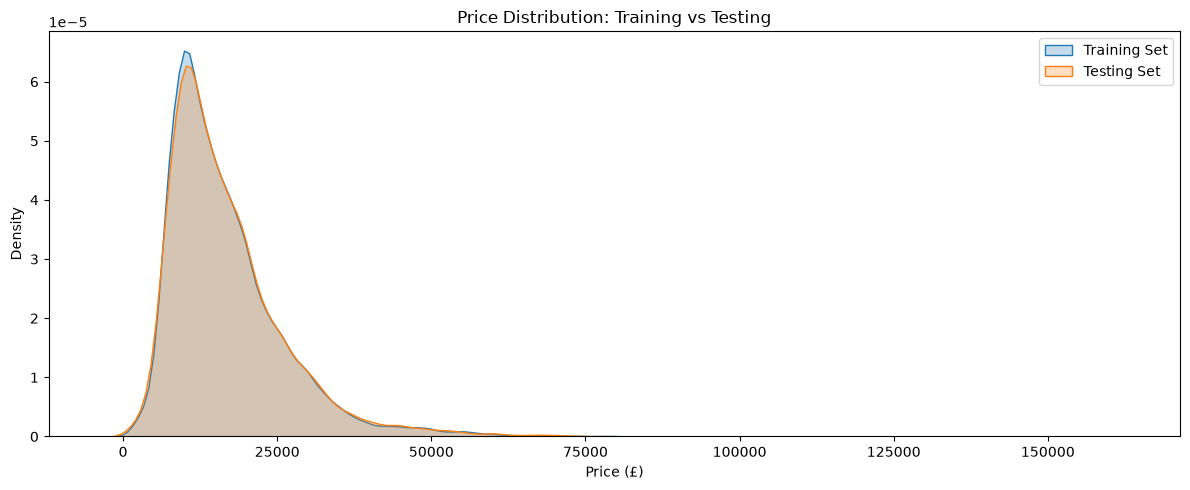

In [ ]:
plt.figure(figsize=(12, 5))

sns.kdeplot(y_train, label="Training Set", fill=True)
sns.kdeplot(y_test, label="Testing Set", fill=True)

plt.title("Price Distribution: Training vs Testing")
plt.xlabel("Price (£)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
missing_values = X_train.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", X_train.isnull().sum().sum())

Missing Values:
engineSize    212
dtype: int64

Total Missing Values: 212


In [ ]:
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X_train.select_dtypes(include=["str", "object"]).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['year', 'mileage', 'tax', 'mpg', 'engineSize']
Categorical Features: ['model', 'transmission', 'fuelType', 'manufacturer']


# Pre Processing

In [ ]:
import sys

sys.path.append(str(PROJECT_ROOT))

from src.preprocessing import (
    create_numerical_pipeline,
    create_categorical_pipeline,
    create_preprocessor
)

print("Preprocessing functions imported successfully.")

Preprocessing functions imported successfully.


In [ ]:
preprocessor = create_preprocessor(
    numerical_features=numerical_features,
    categorical_features=categorical_features
)

print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['year', 'mileage', 'tax', 'mpg',
                                  'engineSize']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['model', 'transmission', 'fuelType',
                                  'manufacturer'])])


In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

print("Processed Training Shape:", X_train_processed.shape)
print("Data Type:", type(X_train_processed))

Processed Training Shape: (78165, 216)
Data Type: <class 'scipy.sparse._csr.csr_matrix'>


In [ ]:
X_test_processed = preprocessor.transform(X_test)

print("Processed Testing Shape:", X_test_processed.shape)
print("Data Type:", type(X_test_processed))

Processed Testing Shape: (19542, 216)
Data Type: <class 'scipy.sparse._csr.csr_matrix'>


In [ ]:
for col in categorical_features:
    print(f"{col}: {X_train[col].nunique()} unique categories")

model: 193 unique categories
transmission: 4 unique categories
fuelType: 5 unique categories
manufacturer: 9 unique categories


In [ ]:
feature_names = preprocessor.get_feature_names_out()

print("Total Features:", len(feature_names))
print("\nFirst 30 Features:")
print(feature_names[:30])

Total Features: 216

First 30 Features:
['num__year' 'num__mileage' 'num__tax' 'num__mpg' 'num__engineSize'
 'cat__model_1 Series' 'cat__model_2 Series' 'cat__model_200'
 'cat__model_220' 'cat__model_230' 'cat__model_3 Series'
 'cat__model_4 Series' 'cat__model_5 Series' 'cat__model_6 Series'
 'cat__model_7 Series' 'cat__model_8 Series' 'cat__model_A Class'
 'cat__model_A1' 'cat__model_A2' 'cat__model_A3' 'cat__model_A4'
 'cat__model_A5' 'cat__model_A6' 'cat__model_A7' 'cat__model_A8'
 'cat__model_Accent' 'cat__model_Adam' 'cat__model_Agila'
 'cat__model_Amarok' 'cat__model_Amica']


In [ ]:
print("Training NaN Values:", np.isnan(X_train_processed.data).sum())
print("Testing NaN Values:", np.isnan(X_test_processed.data).sum())

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training NaN Values: 0
Testing NaN Values: 0
Training Shape: (78165, 216)
Testing Shape: (19542, 216)


In [ ]:
import joblib

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    preprocessor,
    ARTIFACTS_DIR / "preprocessor.joblib"
)

print("Preprocessor saved successfully.")

Preprocessor saved successfully.


In [ ]:
split_data = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test
}

joblib.dump(
    split_data,
    ARTIFACTS_DIR / "train_test_split.joblib"
)

print("Train/Test split saved successfully.")

Train/Test split saved successfully.


In [ ]:
preprocessor_path = ARTIFACTS_DIR / "preprocessor.joblib"
split_path = ARTIFACTS_DIR / "train_test_split.joblib"

print("Preprocessor Exists:", preprocessor_path.exists())
print("Train/Test Split Exists:", split_path.exists())

print("Artifacts Directory:", ARTIFACTS_DIR)

Preprocessor Exists: True
Train/Test Split Exists: True
Artifacts Directory: D:\INSTANT\ML_SV_PROJ\artifacts
